In [1]:
import numpy as np
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs

import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths
import xarray as xr

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
## Upload (LIG-PI) MMM O2, temperature, so
path = '/nfs/hera1/ee22kvcs/PMIP4/'

names_models_mmm = ['o2_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel_v2.nc',
                   'thetao_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel_v2.nc',
                   'so_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel_v2.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2_dif'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao_dif'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'so_dif')]

MMM_models = []
for i in range(np.size(names_models_mmm)):
    uploaded_cubes = iris.load_cube(path+names_models_mmm[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    MMM_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [3]:
## Upload (LIG-PI) MMM O2, temperature, so spread
path = '/nfs/hera1/ee22kvcs/PMIP4/'

names_models_spread = ['o2_spread_non_consensus_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel.nc',
                   'thetao_spread_non_consensus_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel.nc',
                   'so_spread_non_consensus_Oyr_MMM_dif_100yr_mean_regridded_360x385_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'so')]

spread = []
for i in range(np.size(names_models_spread)):
    uploaded_cubes = iris.load_cube(path+names_models_spread[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    spread.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

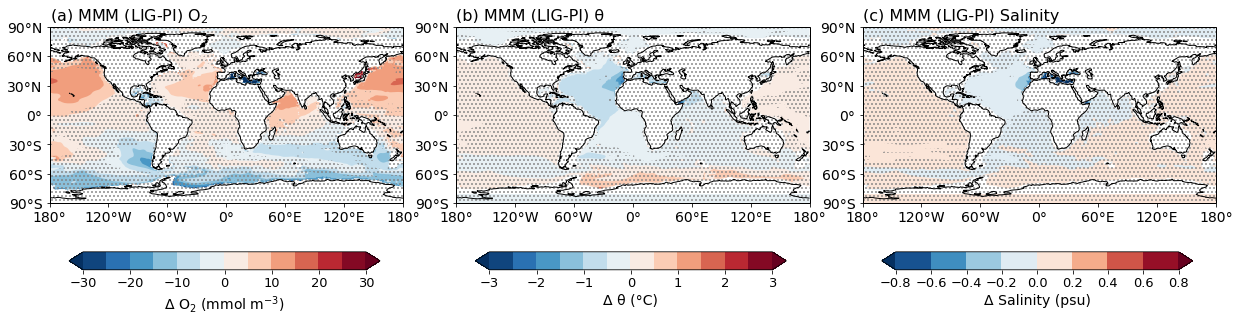

In [4]:
##### Plot
fig = plt.figure(figsize=(18, 5))
proj = ccrs.PlateCarree(central_longitude=0)
axes = []
for i in range(3):
    ax = fig.add_subplot(1, 3, i + 1, projection=proj)
    axes.append(ax)

titles = ['(a) MMM (LIG-PI) O$_2$', '(b) MMM (LIG-PI) θ', '(c) MMM (LIG-PI) Salinity']
cbar_titles = ['Δ O$_2$ (mmol m$^{-3}$)', 'Δ θ (°C)', 'Δ Salinity (psu)']
simulations = [MMM_models[0][51], MMM_models[1][51], MMM_models[2][51]]
spread_mmm  = [spread[0][51],     spread[1][51],     spread[2][51]]
cbar_offsets = [-0.04, 0.0, 0.04] # left, centre, right

# Levels for each variable-
levels = [
    np.arange(-30,  30  + 5,  5),   # O2
    np.arange(-3,  3  + 0.5, 0.5),   # thetao
    np.arange(-0.8,  0.8  + 0.2,  0.2),    # salinity
]

ims = []
for i, ax in enumerate(axes):
    ax.add_feature(cartopy.feature.COASTLINE)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    ax.set_global()
    # Ticks
    ax.set_yticks(np.arange(-90, 91, 30))
    ax.tick_params(axis='y', labelsize=14)
    ax.set_xticks([-180, -120, -60, 0, 60, 120, 180], crs=proj)
    ax.set_xticklabels(['180°', '120°W', '60°W', '0°', '60°E', '120°E', '180°'], fontsize=14)

    ax.set_title(titles[i], fontsize=16, loc='left')

    # contour
    im = iplt.contourf(simulations[i], axes=ax, cmap= 'RdBu_r', levels=levels[i], extend='both')
    ims.append(im)

    # Hatching
    mpl.rcParams['hatch.color'] = 'gray'
    iplt.contourf(spread_mmm[i], levels=[0.5, 1.5],colors='none', hatches=['...'], axes=ax)

    # colourbars
    # Get subplot position to place colorbar directly beneath it
    pos = ax.get_position()          # [x0, y0, width, height]
    cbar_ax = fig.add_axes([pos.x0 + cbar_offsets[i], pos.y0, 0.24, 0.05])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label(cbar_titles[i], size=14)
    cbar.ax.tick_params(labelsize=13)

plt.subplots_adjust(left=0.07, right=0.97, bottom=0.18, top=0.93, wspace=0.15, hspace=0.05)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/global_mmm_o2_thetao_so.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

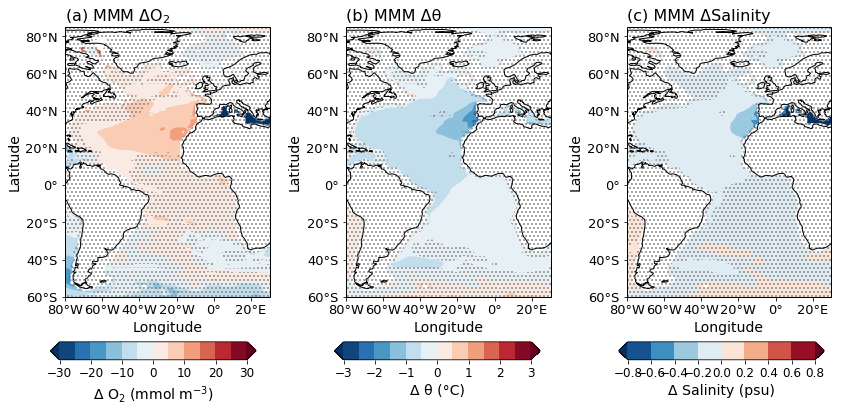

In [6]:
#### Plot
fig = plt.figure(figsize=(13, 5))
proj = ccrs.PlateCarree(central_longitude=0)
axes = []
for i in range(3):
    ax = fig.add_subplot(1, 3, i + 1, projection=proj)
    axes.append(ax)

titles = ['(a) MMM ΔO$_2$', '(b) MMM Δθ', '(c) MMM ΔSalinity']
cbar_titles = ['Δ O$_2$ (mmol m$^{-3}$)', 'Δ θ (°C)', 'Δ Salinity (psu)']
simulations = [MMM_models[0][51], MMM_models[1][51], MMM_models[2][51]]
spread_mmm  = [spread[0][51],     spread[1][51],     spread[2][51]]

# Levels
levels = [np.arange(-30,  30  + 5,  5),   # O2
    np.arange(-3,  3  + 0.5, 0.5),   # thetao
    np.arange(-0.8,  0.8  + 0.2,  0.2),    # salinity
         ]
cbar_offsets = [-0.03, 0.0, 0.03]  # left, centre, right

# Atlantic Ocean
atl_xlim = (-80, 30)
atl_ylim = (-60, 85)

ims = []
for i, ax in enumerate(axes):
    ax.add_feature(cartopy.feature.COASTLINE)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    
    # Atlantic extent
    ax.set_xlim(atl_xlim)
    ax.set_ylim(atl_ylim)

    # Ticks
    xticks = [-80, -60, -40, -20, 0, 20]
    yticks = np.arange(-60, 90, 20)
    ax.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax.set_yticks(yticks,  crs=ccrs.PlateCarree())
    # Axis labels
    ax.set_xlabel('Longitude', fontsize=14)
    ax.set_ylabel('Latitude', fontsize=14)
    
    ax.tick_params(axis='both', labelsize=13)
    ax.set_title(titles[i], fontsize=16, loc='left')

    # contour
    im = iplt.contourf(simulations[i], axes=ax, cmap= 'RdBu_r', levels=levels[i], extend='both')
    ims.append(im)

    # Hatching
    mpl.rcParams['hatch.color'] = 'gray'
    iplt.contourf(spread_mmm[i], levels=[0.5, 1.5],colors='none', hatches=['...'], axes=ax)

    # colourbars
    pos = ax.get_position()
    cbar_ax = fig.add_axes([pos.x0 + cbar_offsets[i], pos.y0 - 0.12, 0.22, 0.05])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label(cbar_titles[i], size=14)
    cbar.ax.tick_params(labelsize=12)

plt.subplots_adjust(left=0.07, right=0.97, bottom=0.18, top=0.93, wspace=0.001, hspace=0.05)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Atlantic_mmm_1500m_o2_thetao_so_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()